In [1]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"laibaimran01","key":"90967feed9698876527595c09a9766f6"}'}

In [2]:
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d puneet6060/intel-image-classification
!unzip -q intel-image-classification.zip -d data
!ls data

Dataset URL: https://www.kaggle.com/datasets/puneet6060/intel-image-classification
License(s): copyright-authors
100% 346M/346M [00:02<00:00, 150MB/s]

seg_pred  seg_test  seg_train


In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG = (150, 150)
BATCH = 32
train_dir = "data/seg_train/seg_train"
test_dir  = "data/seg_test/seg_test"

train_ds = keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.15, subset="training", seed=42,
    image_size=IMG, batch_size=BATCH)
val_ds = keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.15, subset="validation", seed=42,
    image_size=IMG, batch_size=BATCH)
test_ds = keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
print(class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 14034 files belonging to 6 classes.
Using 11929 files for training.
Found 14034 files belonging to 6 classes.
Using 2105 files for validation.
Found 3000 files belonging to 6 classes.
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [4]:
aug = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

base = keras.applications.MobileNetV2(
    input_shape=IMG + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=IMG + (3,))
x = aug(inputs)
x = layers.Rescaling(1/127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(6, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = model.fit(train_ds, validation_data=val_ds, epochs=8)

base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=8)

/tmp/ipykernel_689/1168577273.py:7: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
373/373 ━━━━━━━━━━━━━━━━━━━━ 22s 39ms/step - accuracy: 0.7766 - loss: 0.6257 - val_accuracy: 0.8812 - val_loss: 0.3316
Epoch 2/8
373/373 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.8440 - loss: 0.4397 - val_accuracy: 0.8822 - val_loss: 0.3205
Epoch 3/8
373/373 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.8537 - loss: 0.4103 - val_accuracy: 0.8822 - val_loss: 0.3228
Epoch 4/8
373/373 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.8629 - loss: 0.3827 - val_accuracy: 0.8869 - val_loss: 0.3073
Epoch 5/8
373/373 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8638 - loss: 0.3808 - val_accuracy: 0.8779 - val_loss: 0.3390
Epoch 6/8
373/373 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8683 - loss: 0.3646 - val_accuracy: 0.8717 - val_loss: 0.3491
Epoch 7/8
373/373 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8653 - loss: 0.3690 - val_accuracy: 0.8827 - val_loss: 0.3192
Epoch 8/8
373/373 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9040 - loss: 0.2533
[0.25331634283065796, 0.9039999842643738]
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step
              precision    recall  f1-score   support

   buildings       0.86      0.95      0.90       437
      forest       0.99      0.99      0.99       474
     glacier       0.85      0.84      0.85       553
    mountain       0.86      0.84      0.85       525
         sea       0.93      0.94      0.93       510
      street       0.95      0.89      0.92       501

    accuracy                           0.90      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.90      0.90      0.90      3000



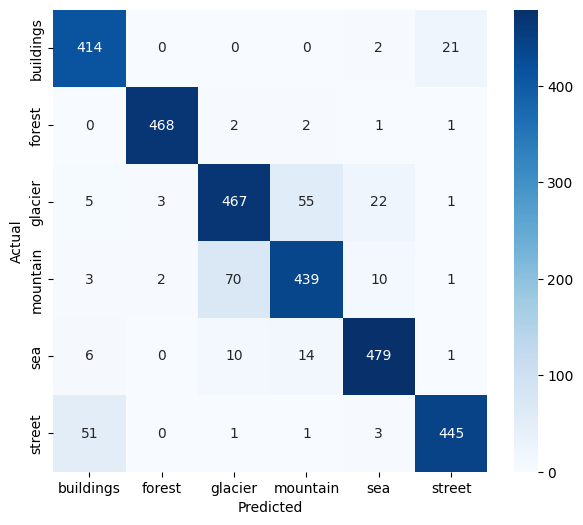

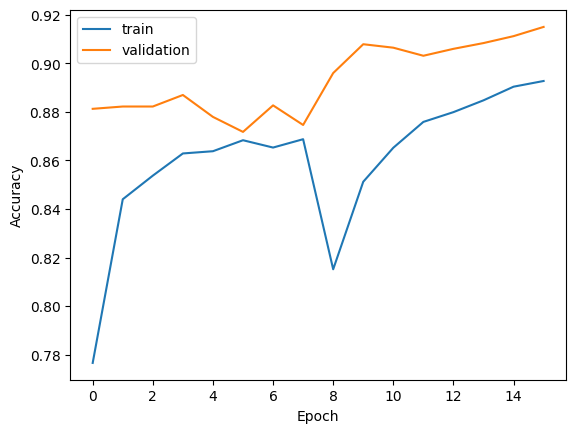

In [5]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print(model.evaluate(test_ds))

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_true, y_pred, target_names=class_names))

plt.figure(figsize=(7,6))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d",
            xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

acc = h1.history["accuracy"] + h2.history["accuracy"]
val = h1.history["val_accuracy"] + h2.history["val_accuracy"]
plt.plot(acc, label="train"); plt.plot(val, label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.savefig("accuracy_curve.png", dpi=150, bbox_inches="tight"); plt.show()


In [6]:
from google.colab import files
model.save("model.h5")
!pip install -q tensorflowjs
!tensorflowjs_converter --input_format=keras model.h5 tfjs_model
!zip -r tfjs_model.zip tfjs_model
files.download("model.h5")
files.download("tfjs_model.zip")
files.download("confusion_matrix.png")
files.download("accuracy_curve.png")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pandas-gbq 0.30.0 requires packaging>=22.0.0, but you have packaging 20.9 which is incompatible.
astropy 7.2.3 requires packaging>=22.0.0, but you have packaging 20.9 which is incompatible.
xarray 2025.12.0 requires packaging>=24.1, but you have packaging 20.9 which is incompatible.
google-cloud-bigquery 3.46.2 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
google-adk 2.7.1 requires packaging>=21, but you have packaging 20.9 which is incompatible.
bigquery-magics 0.14.0 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
jupyter-server 2.20.0 requires packaging>=22.0, but you have packaging 20.9 which is incompatible.
langc

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FileNotFoundError: Cannot find file: tfjs_model.zip

In [7]:
!pip install -q tensorflowjs 2>&1 | tail -5
!tensorflowjs_converter --input_format=keras model.h5 tfjs_model 2>&1 | tail -15
!ls tfjs_model

    from tensorflowjs.converters import keras_h5_conversion as conversion
  File "/usr/local/lib/python3.13/dist-packages/tensorflowjs/converters/keras_h5_conversion.py", line 33, in <module>
    from tensorflowjs import write_weights  # pylint: disable=import-error
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/tensorflowjs/write_weights.py", line 25, in <module>
    from tensorflowjs import read_weights
  File "/usr/local/lib/python3.13/dist-packages/tensorflowjs/read_weights.py", line 28, in <module>
    np.uint8, np.uint16, np.object, np.bool]
                         ^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/numpy/__init__.py", line 397, in __getattr__
    raise AttributeError(__former_attrs__[attr], name=None)
AttributeError: module 'numpy' has no attribute 'object'.
`np.object` was a deprecated alias for the builtin `object`. To avoid this error in existing code, use `object` by itself. Doing this will not modify any be

In [8]:
from google.colab import files
files.download("confusion_matrix.png")
files.download("accuracy_curve.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
!sed -i -E 's/np\.object\b/object/g; s/np\.bool\b/bool/g' /usr/local/lib/python3.13/dist-packages/tensorflowjs/*.py /usr/local/lib/python3.13/dist-packages/tensorflowjs/converters/*.py
!tensorflowjs_converter --input_format=keras model.h5 tfjs_model 2>&1 | tail -15
!ls tfjs_model

    from tensorflowjs import converters
  File "/usr/local/lib/python3.13/dist-packages/tensorflowjs/converters/__init__.py", line 21, in <module>
    from tensorflowjs.converters.converter import convert
  File "/usr/local/lib/python3.13/dist-packages/tensorflowjs/converters/converter.py", line 37, in <module>
    from tensorflowjs.converters import tf_saved_model_conversion_v2
  File "/usr/local/lib/python3.13/dist-packages/tensorflowjs/converters/tf_saved_model_conversion_v2.py", line 42, in <module>
    import tensorflow_hub as hub
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py", line 88, in <module>
    from tensorflow_hub.estimator import LatestModuleExporter
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_hub/estimator.py", line 62, in <module>
    class LatestModuleExporter(tf.compat.v1.estimator.Exporter):
                               ^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/util/module_wr

In [10]:
from google.colab import files
!zip -r tfjs_model.zip tfjs_model
files.download("tfjs_model.zip")

	zip warning: name not matched: tfjs_model

zip error: Nothing to do! (try: zip -r tfjs_model.zip . -i tfjs_model)


FileNotFoundError: Cannot find file: tfjs_model.zip

In [11]:
import tensorflow as tf, keras
print("TF", tf.__version__, "Keras", keras.__version__)
model.save("model.keras")
from google.colab import files
files.download("model.keras")

TF 2.21.0 Keras 3.13.2


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import numpy as np
from sklearn.metrics import classification_report

print(model.evaluate(test_ds))
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_true, y_pred, target_names=class_names))

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.9040 - loss: 0.2533
[0.25331634283065796, 0.9039999842643738]
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step
              precision    recall  f1-score   support

   buildings       0.86      0.95      0.90       437
      forest       0.99      0.99      0.99       474
     glacier       0.85      0.84      0.85       553
    mountain       0.86      0.84      0.85       525
         sea       0.93      0.94      0.93       510
      street       0.95      0.89      0.92       501

    accuracy                           0.90      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.90      0.90      0.90      3000



In [1]:
import os
if not os.path.exists("data/seg_train"):
    from google.colab import files
    files.upload()   # choose kaggle.json again
    !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
    !kaggle datasets download -d puneet6060/intel-image-classification
    !unzip -q intel-image-classification.zip -d data

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG = (150, 150)
BATCH = 32
train_dir = "data/seg_train/seg_train"
test_dir  = "data/seg_test/seg_test"

train_ds = keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.15, subset="training", seed=42,
    image_size=IMG, batch_size=BATCH)
val_ds = keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.15, subset="validation", seed=42,
    image_size=IMG, batch_size=BATCH)
test_ds = keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
print(class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/puneet6060/intel-image-classification
License(s): copyright-authors
100% 346M/346M [00:23<00:00, 15.4MB/s]

Found 14034 files belonging to 6 classes.
Using 11929 files for training.
Found 14034 files belonging to 6 classes.
Using 2105 files for validation.
Found 3000 files belonging to 6 classes.
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [2]:
aug = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

def block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return layers.MaxPooling2D()(x)

inputs = keras.Input(shape=IMG + (3,))
x = aug(inputs)
x = layers.Rescaling(1/255)(x)
for f in (32, 64, 128, 256):
    x = block(x, f)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(6, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

callbacks = [
    keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 75, 75, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 75, 75, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 37, 37, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 37, 37, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,208,806 (4.61 MB)

 Trainable params: 1,206,886 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 67s 149ms/step - accuracy: 0.5564 - loss: 1.1221 - val_accuracy: 0.4665 - val_loss: 1.5263 - learning_rate: 0.0010
Epoch 2/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 56s 150ms/step - accuracy: 0.6822 - loss: 0.8518 - val_accuracy: 0.4299 - val_loss: 2.2054 - learning_rate: 0.0010
Epoch 3/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 55s 148ms/step - accuracy: 0.7348 - loss: 0.7391 - val_accuracy: 0.5729 - val_loss: 1.6632 - learning_rate: 0.0010
Epoch 4/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 55s 148ms/step - accuracy: 0.7589 - loss: 0.6702 - val_accuracy: 0.6903 - val_loss: 0.9731 - learning_rate: 0.0010
Epoch 5/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 55s 148ms/step - accuracy: 0.7699 - loss: 0.6510 - val_accuracy: 0.5477 - val_loss: 1.4663 - learning_rate: 0.0010
Epoch 6/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 55s 148ms/step - accuracy: 0.7879 - loss: 0.6017 - val_accuracy: 0.5154 - val_loss: 1.9429 - learning_rate: 0.0010
Epoch 7/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 55s 149ms/step - accuracy: 0.7

In [3]:
model.compile(optimizer=keras.optimizers.Adam(3e-4),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_accuracy", factor=0.5, patience=2, min_lr=1e-5),
]
history2 = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=callbacks)


Epoch 1/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 61s 153ms/step - accuracy: 0.8565 - loss: 0.4083 - val_accuracy: 0.7435 - val_loss: 0.7404 - learning_rate: 3.0000e-04
Epoch 2/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 56s 149ms/step - accuracy: 0.8624 - loss: 0.3903 - val_accuracy: 0.7169 - val_loss: 0.8443 - learning_rate: 3.0000e-04
Epoch 3/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 56s 149ms/step - accuracy: 0.8685 - loss: 0.3744 - val_accuracy: 0.7715 - val_loss: 0.7051 - learning_rate: 3.0000e-04
Epoch 4/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 83s 152ms/step - accuracy: 0.8711 - loss: 0.3759 - val_accuracy: 0.6722 - val_loss: 1.1215 - learning_rate: 3.0000e-04
Epoch 5/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 55s 148ms/step - accuracy: 0.8698 - loss: 0.3748 - val_accuracy: 0.5154 - val_loss: 1.9110 - learning_rate: 3.0000e-04
Epoch 6/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 55s 148ms/step - accuracy: 0.8804 - loss: 0.3480 - val_accuracy: 0.7800 - val_loss: 0.6297 - learning_rate: 1.5000e-04
Epoch 7/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 55s 14

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.8410 - loss: 0.4644
[0.4644017219543457, 0.8410000205039978]
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step
              precision    recall  f1-score   support

   buildings       0.73      0.91      0.81       437
      forest       0.98      0.95      0.97       474
     glacier       0.88      0.70      0.78       553
    mountain       0.82      0.75      0.78       525
         sea       0.79      0.92      0.85       510
      street       0.88      0.84      0.86       501

    accuracy                           0.84      3000
   macro avg       0.85      0.85      0.84      3000
weighted avg       0.85      0.84      0.84      3000



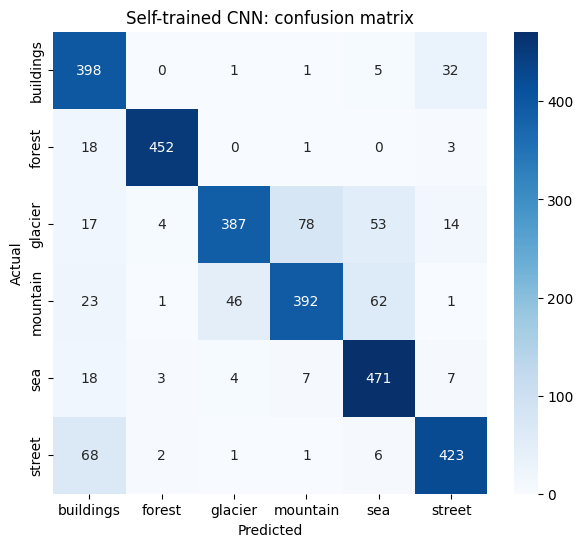

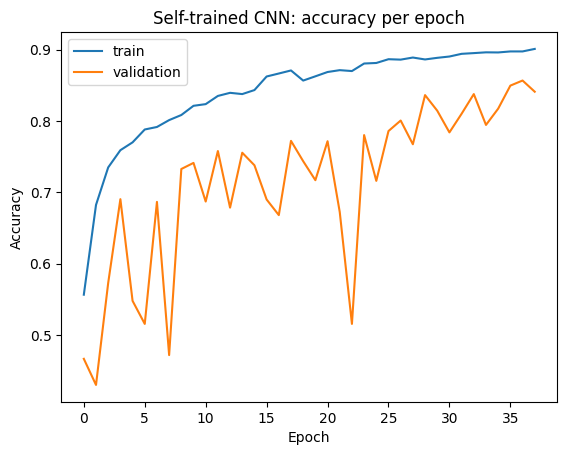

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from google.colab import files

print(model.evaluate(test_ds))
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_true, y_pred, target_names=class_names))

plt.figure(figsize=(7,6))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d",
            xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Self-trained CNN: confusion matrix")
plt.savefig("scratch_confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

acc = history.history["accuracy"] + history2.history["accuracy"]
val = history.history["val_accuracy"] + history2.history["val_accuracy"]
plt.plot(acc, label="train"); plt.plot(val, label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.title("Self-trained CNN: accuracy per epoch")
plt.savefig("scratch_accuracy_curve.png", dpi=150, bbox_inches="tight"); plt.show()

model.save("model_scratch.keras")
files.download("model_scratch.keras")
files.download("scratch_confusion_matrix.png")
files.download("scratch_accuracy_curve.png")